### Check toyota notebooks for regression models and SHAP explanations extraction

In [2]:
from cmath import exp
import sys
from threading import local
import pandas as pd
import numpy as np
import shap
from xgboost.sklearn import XGBClassifier
from sklearn.metrics import r2_score
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
import sys 
import os

TRAIN MODEL

In [5]:
from sklearn.neural_network import MLPClassifier
# train original model and get its predictions
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
original_model = MLPClassifier()
original_model.fit(X_train, y_train)
predictions = original_model.predict(X)

In [6]:
# explain all the predictions in the test set
explainer = shap.KernelExplainer(original_model.predict_proba, X_train)
shap_values = explainer.shap_values(X_test)

Using 455 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
  0%|          | 0/114 [00:00<?, ?it/s]The default of 'normalize' will be set to False in version 1.2 and deprecated in version 1.4.
If you wish to scale the data, use Pipeline with a StandardScaler in a preprocessing stage. To reproduce the previous behavior:

from sklearn.pipeline import make_pipeline

model = make_pipeline(StandardScaler(with_mean=False), LassoLarsIC())

If you wish to pass a sample_weight parameter, you need to pass it as a fit parameter to each step of the pipeline as follows:

kwargs = {s[0] + '__sample_weight': sample_weight for s in model.steps}
model.fit(X, y, **kwargs)

Set parameter alpha to: original_alpha * np.sqrt(n_samples). 
The default of 'normalize' will be set to False in version 1.2 and deprecated in version 1.4.
If you wish to scale the data, use Pipeline with a StandardScaler in a pre

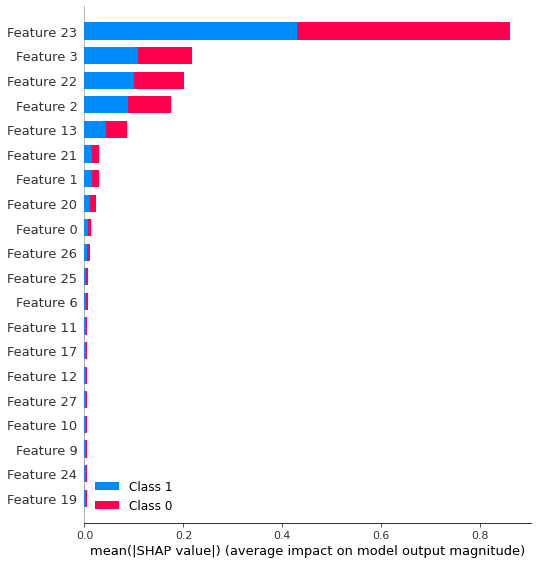

In [7]:
shap.summary_plot(shap_values, X_test, plot_type="bar")

CALCULATE SHAP VALUES

In [ ]:
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

EXTRACT SHAP VALUES

In [16]:
feature_names = shap_values.feature_names
shap_df = pd.DataFrame(shap_values.values, columns=feature_names)
vals = np.abs(shap_df.values).mean(0)
shap_importance = pd.DataFrame(list(zip(feature_names, vals)), columns=['col_name', 'feature_importance_vals'])
shap_importance.sort_values(by=['feature_importance_vals'], ascending=False, inplace=True)

AttributeError: 'list' object has no attribute 'feature_names'

In [17]:
vals = np.abs(shap_values.values).mean(0)
feature_names = X_train.columns()

feature_importance = pd.DataFrame(list(zip(feature_names, vals)),
                                 columns=['col_name','feature_importance_vals'])
feature_importance.sort_values(by=['feature_importance_vals'],
                              ascending=False, inplace=True)
feature_importance.head()

AttributeError: 'list' object has no attribute 'values'

In [9]:
# ----------- Extract global explanations -----------
vals= np.abs(shap_values).mean(0)

X_train = pd.DataFrame(X_train)

feature_importance = pd.DataFrame(list(zip(X_train.columns,vals)),columns=['col_name','feature_importance_vals'])
feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
feature_importance["col_name"] =  'Feature ' + feature_importance["col_name"].astype(str)

feature_importance = feature_importance.head()

feature_importance.to_csv(r'C:\Users\Stefanos Rigas\Documents\Projects\Thesis\thesis\robustness-evaluation\explanations\G_E_MASHAP\features.txt', header=None, index=None, sep=' ', mode='a')

with open(r'C:\Users\Stefanos Rigas\Documents\Projects\Thesis\thesis\robustness-evaluation\explanations\G_E_SHAP\features.txt','a') as file:
    file.write("\nRun number: 2\n\n")
file.close()

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

IMPLEMENT LOOP SCRIPT